In [1]:
import pandas as pd
import os

# Path to our raw dataset
file_path = "../data/raw/SMSSpamCollection"

# Load the tab-separated dataset
df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
# Basic information
print("Number of messages:", len(df))
print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate messages:", df["message"].duplicated().sum())

Number of messages: 5572

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64

Duplicate messages: 403


In [3]:
# Convert labels to readable counts
label_counts = df["label"].value_counts()

print(f"Ham messages: {label_counts.get('ham', 0)}")
print(f"Spam messages: {label_counts.get('spam', 0)}")

Ham messages: 4825
Spam messages: 747


In [4]:
# Display some spam examples
print("SPAM EXAMPLES:\n")
display(df[df["label"] == "spam"].head(10))

print("\nHAM EXAMPLES:\n")
display(df[df["label"] == "ham"].head(10))

SPAM EXAMPLES:



,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
5,spam,FreeMsg Hey there darling it's been 3 week's n...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."
12,spam,URGENT! You have won a 1 week FREE membership ...
15,spam,"XXXMobileMovieClub: To use your credit, click ..."
19,spam,England v Macedonia - dont miss the goals/team...
34,spam,Thanks for your subscription to Ringtone UK yo...
42,spam,07732584351 - Rodger Burns - MSG = We tried to...



HAM EXAMPLES:



,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
10,ham,I'm gonna be home soon and i don't want to tal...
13,ham,I've been searching for the right words to tha...
14,ham,I HAVE A DATE ON SUNDAY WITH WILL!!
16,ham,Oh k...i'm watching here:)


Matplotlib is building the font cache; this may take a moment.


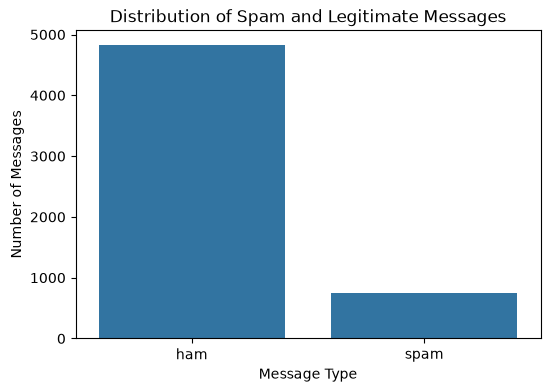

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label")
plt.title("Distribution of Spam and Legitimate Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()

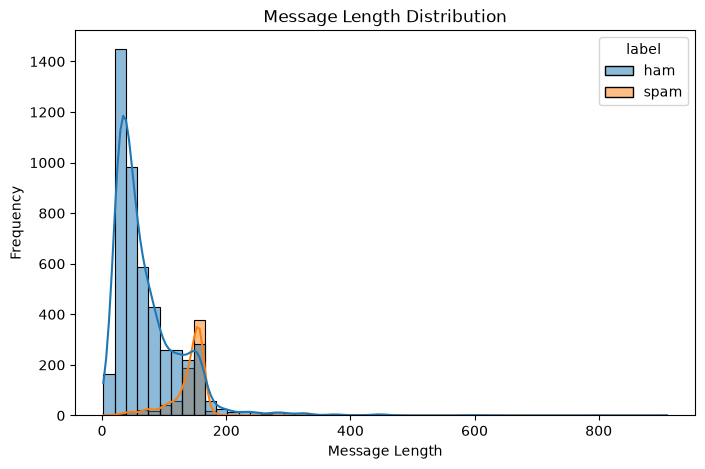

In [6]:
df["message_length"] = df["message"].apply(len)

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="message_length",
    hue="label",
    bins=50,
    kde=True
)
plt.title("Message Length Distribution")
plt.xlabel("Message Length")
plt.ylabel("Frequency")
plt.show()

In [7]:
# Remove duplicate messages
df = df.drop_duplicates(subset="message").copy()

# Remove rows with missing values
df = df.dropna(subset=["label", "message"]).copy()

# Normalize labels
df["label"] = df["label"].str.lower().str.strip()

print("Dataset after cleaning:", df.shape)
print(df["label"].value_counts())

Dataset after cleaning: (5169, 3)
label
ham     4516
spam     653
Name: count, dtype: int64


In [8]:
processed_df = df[["label", "message"]].copy()

In [9]:
processed_path = "../data/processed/cleaned_spam_dataset.csv"

processed_df.to_csv(processed_path, index=False)

print("Processed dataset saved to:", processed_path)

Processed dataset saved to: ../data/processed/cleaned_spam_dataset.csv
